# Model 2 - FloodNet: Teammate 2 - train 2 models

This notebook trains **pspnet_r50** and then **unet_r50_scse_hybrid**, one after the other.
The other teammate's notebook trains the other 2 of the 4 models; together they
fill the comparison table. Every model uses the same data, crop, schedule,
epochs and seed - only the model/loss differs - so the 4 results are fair to compare.

| # | model | what it is |
|---|---|---|
| 1 | `pspnet_r50` | PSPNet, ResNet-50, cross-entropy - the FloodNet paper's best model |
| 2 | `unet_r50_scse_hybrid` | **ours**: U-Net R50 + scSE attention + Dice/Focal loss |

`Runtime > Change runtime type > GPU (T4)`. Expect **~2-3 h per model**.

**Disconnected, or the session ran out?** Run every cell again from the top.
A finished model is skipped and an unfinished one resumes from its last epoch
(checkpoints are on your Drive). Nothing to change.

## 1. Settings - the only cell you edit

In [12]:
DATA_LINK = 'https://drive.google.com/file/d/16IurlaaxAF0OYjN_MN-w3Jgh8NguGwJg/view?usp=sharing'   # @param {type:"string"}
# DATA_LINK: the share link of floodnet_1024.zip you were sent.
# Leave empty if floodnet_1024.zip is already in your own MyDrive/FloodSeg/.

RUNS = ["pspnet_r50", "unet_r50_scse_hybrid"]   # fixed - do not change
EPOCHS, SEED = 80, 0        # fixed - must match the other teammate

## 2. GPU + Drive

In [13]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
from google.colab import drive
drive.mount('/content/drive')
import os
FS = '/content/drive/MyDrive/FloodSeg'
os.makedirs(FS, exist_ok=True)
DATA = '/content/floodnet_1024'

name, memory.total [MiB]
Tesla T4, 15360 MiB
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Get the prepared dataset onto local disk (~1 min)

In [14]:
if not os.path.isdir(f'{DATA}/train/images'):
    ZIP = f'{FS}/floodnet_1024.zip'
    if not os.path.exists(ZIP):
        assert DATA_LINK, 'Set DATA_LINK in cell 1 (or put floodnet_1024.zip in MyDrive/FloodSeg/)'
        ZIP = '/content/floodnet_1024.zip'
        !gdown -q --fuzzy "{DATA_LINK}" -O {ZIP}
    !mkdir -p {DATA} && unzip -q {ZIP} -d {DATA}
for s in ['train', 'val', 'test']:
    print(s, len(os.listdir(f'{DATA}/{s}/images')), 'images')

train 1445 images
val 450 images
test 448 images


## 4. Install + write the training script

In [15]:
!pip -q install "segmentation-models-pytorch>=0.5" "albumentations>=1.4"
import segmentation_models_pytorch as smp, torch
print('smp', smp.__version__, '| torch', torch.__version__, '| cuda', torch.cuda.is_available())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.0 MB/s eta 0:00:00
smp 0.5.0 | torch 2.11.0+cu130 | cuda True


In [16]:
%%writefile /content/floodnet_train.py
"""
Model 2 - Step 2: Train / evaluate one FloodNet segmentation run.

Every run uses the SAME data (official FloodNet split, cached at 1024x768),
crop (512), schedule, optimiser, epochs, seed and evaluation - only the
model and loss change. That is what makes the comparison table fair.

Runs (pick one with --run), all with a ResNet-50 encoder:
  baselines   unet_r50, deeplabv3p_r50, pspnet_r50                  (cross-entropy)
  ours        unet_r50_scse_hybrid = unet_r50 + scSE attention + Dice/Focal loss,
              so unet_r50 -> ours isolates exactly what our changes add

Metrics on the official TEST split, at 1024x768:
  * mIoU over the 9 non-background classes - the definition used by the
    FloodNet paper's Table 4 (PSPNet 79.69), so it is the headline number
  * mIoU over all 10 classes, pixel accuracy, per-class IoU
  * parameters and FPS (batch 1, 1024x768, fp16) on the GPU that ran it

Checkpoints go to <out>/runs/<run>/ every epoch; re-running the same command
resumes automatically. When finished, <out>/results/<run>.json holds
everything the comparison table needs.

Usage (Colab):
    python floodnet_train.py --run unet_r50 --data /content/floodnet_1024 \\
                             --out /content/drive/MyDrive/FloodSeg
"""

import argparse
import json
import math
import random
import time
from pathlib import Path

import albumentations as A
import cv2
import numpy as np
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

CLASSES = ["background", "building-flooded", "building-non-flooded", "road-flooded",
           "road-non-flooded", "water", "tree", "vehicle", "pool", "grass"]
NC = len(CLASSES)
HARD = ["building-flooded", "road-flooded", "vehicle", "pool"]
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)
PALETTE = np.array([[0, 0, 0], [255, 0, 0], [180, 120, 120], [160, 150, 20], [140, 140, 140],
                    [61, 230, 250], [0, 82, 255], [255, 0, 245], [255, 235, 0], [4, 250, 7]],
                   np.uint8)

RUNS = {
    # --- baselines: standard cross-entropy -----------------------------------
    "unet_r50":             dict(arch="Unet", encoder="resnet50", attention=None, loss="ce"),
    "deeplabv3p_r50":       dict(arch="DeepLabV3Plus", encoder="resnet50", attention=None, loss="ce"),
    "pspnet_r50":           dict(arch="PSPNet", encoder="resnet50", attention=None, loss="ce"),
    # --- ours: unet_r50 + scSE attention + Dice/Focal --------------------------
    "unet_r50_scse_hybrid": dict(arch="Unet", encoder="resnet50", attention="scse", loss="hybrid"),
}


# ----------------------------------------------------------------------------- data
class FloodNet(Dataset):
    def __init__(self, root, split, crop=0):
        self.imgs = sorted((Path(root) / split / "images").glob("*.jpg"))
        if not self.imgs:
            raise SystemExit(f"no images in {Path(root) / split / 'images'} - run floodnet_prep.py")
        self.masks = [p.parent.parent / "masks" / f"{p.stem}.png" for p in self.imgs]
        self.aug = A.Compose([
            A.RandomScale(scale_limit=(-0.25, 0.25), p=0.5),
            A.RandomCrop(crop, crop),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomRotate90(p=0.5),   # nadir drone view: no "up" direction
            A.RandomBrightnessContrast(0.2, 0.2, p=0.5),
        ]) if crop else None

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(str(self.imgs[i])), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(str(self.masks[i]), cv2.IMREAD_UNCHANGED)
        if self.aug:
            r = self.aug(image=img, mask=mask)
            img, mask = r["image"], r["mask"]
        x = (img.astype(np.float32) / 255.0 - MEAN) / STD
        return torch.from_numpy(x.transpose(2, 0, 1).copy()), torch.from_numpy(mask.astype(np.int64))


# ----------------------------------------------------------------------------- model / loss
def build_model(cfg, weights="imagenet"):
    kw = dict(encoder_name=cfg["encoder"], encoder_weights=weights, classes=NC)
    if cfg["arch"] == "Unet":
        return smp.Unet(decoder_attention_type=cfg["attention"], **kw)
    if not hasattr(smp, cfg["arch"]):
        raise SystemExit(f"smp {smp.__version__} has no {cfg['arch']} - pip install -U segmentation-models-pytorch")
    return getattr(smp, cfg["arch"])(**kw)


class Hybrid(nn.Module):
    """Dice (region overlap, insensitive to class frequency) + Focal (hard pixels)."""
    def __init__(self):
        super().__init__()
        self.dice = smp.losses.DiceLoss("multiclass", from_logits=True)
        self.focal = smp.losses.FocalLoss("multiclass")

    def forward(self, logits, y):
        return self.dice(logits, y) + self.focal(logits, y)


def build_loss(name):
    return nn.CrossEntropyLoss() if name == "ce" else Hybrid()


def forward(model, x):
    out = model(x)
    if out.shape[-2:] != x.shape[-2:]:      # guard: every arch must predict at input size
        out = F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False)
    return out


# ----------------------------------------------------------------------------- metrics
@torch.no_grad()
def confusion(model, loader, device):
    model.eval()
    cm = torch.zeros(NC, NC, dtype=torch.int64, device=device)
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, enabled=device.type == "cuda"):
            pred = forward(model, x).argmax(1)
        cm += torch.bincount(y.view(-1) * NC + pred.view(-1), minlength=NC * NC).view(NC, NC)
    return cm.cpu().numpy()


def scores(cm):
    tp = np.diag(cm).astype(np.float64)
    denom = cm.sum(0) + cm.sum(1) - tp
    iou = np.where(denom > 0, tp / np.maximum(denom, 1), np.nan)
    return {
        "mIoU9": round(float(np.nanmean(iou[1:]) * 100), 2),    # FloodNet paper definition
        "mIoU10": round(float(np.nanmean(iou) * 100), 2),
        "pixel_acc": round(float(tp.sum() / cm.sum() * 100), 2),
        "per_class_IoU": {c: (None if np.isnan(v) else round(float(v * 100), 2))
                          for c, v in zip(CLASSES, iou)},
    }


@torch.no_grad()
def measure_fps(model, device, h, w, n=50):
    if device.type != "cuda":
        return None
    model.eval()
    x = torch.randn(1, 3, h, w, device=device)
    with torch.autocast("cuda"):
        for _ in range(10):
            forward(model, x)
        torch.cuda.synchronize()
        t = time.perf_counter()
        for _ in range(n):
            forward(model, x)
        torch.cuda.synchronize()
    return round(n / (time.perf_counter() - t), 1)


def save_predictions(model, ds, device, path, n=4):
    model.eval()
    rows = []
    for i in np.linspace(0, len(ds) - 1, n).astype(int):
        x, y = ds[i]
        with torch.no_grad(), torch.autocast(device.type, enabled=device.type == "cuda"):
            pred = forward(model, x[None].to(device)).argmax(1)[0].cpu().numpy()
        img = ((x.numpy().transpose(1, 2, 0) * STD + MEAN) * 255).clip(0, 255).astype(np.uint8)
        rows.append(np.concatenate([img, PALETTE[y.numpy()], PALETTE[pred]], 1))
    out = np.concatenate(rows, 0)
    out = cv2.resize(out, (out.shape[1] // 2, out.shape[0] // 2), interpolation=cv2.INTER_NEAREST)
    cv2.imwrite(str(path), cv2.cvtColor(out, cv2.COLOR_RGB2BGR))


# ----------------------------------------------------------------------------- main
def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--run", required=True, choices=sorted(RUNS))
    ap.add_argument("--data", required=True, help="output dir of floodnet_prep.py")
    ap.add_argument("--out", required=True, help="put on Google Drive: checkpoints + results")
    ap.add_argument("--epochs", type=int, default=80)
    ap.add_argument("--batch", type=int, default=8)
    ap.add_argument("--crop", type=int, default=512)
    ap.add_argument("--lr", type=float, default=2e-4)
    ap.add_argument("--weight-decay", type=float, default=1e-4)
    ap.add_argument("--val-every", type=int, default=2)
    ap.add_argument("--workers", type=int, default=2)
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--eval-only", action="store_true", help="skip training, re-evaluate best.pt")
    ap.add_argument("--max-steps", type=int, default=0, help="debug: stop each epoch after N steps")
    ap.add_argument("--no-pretrained", action="store_true", help="debug: skip ImageNet weights download")
    args = ap.parse_args()

    cfg = RUNS[args.run]
    tag = args.run if args.seed == 0 else f"{args.run}_seed{args.seed}"
    run_dir = Path(args.out) / "runs" / tag
    res_path = Path(args.out) / "results" / f"{tag}.json"
    run_dir.mkdir(parents=True, exist_ok=True)
    res_path.parent.mkdir(parents=True, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    gpu = torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"
    print(f"[run] {tag}: {cfg}  on {gpu}")
    if device.type != "cuda":
        print("[warn] no GPU - only useful for a smoke test")

    if res_path.exists() and not args.eval_only:
        raise SystemExit(f"{res_path} exists - this run is finished. Use --eval-only to re-evaluate.")

    seed_all(args.seed)
    train_ds = FloodNet(args.data, "train", crop=args.crop)
    val_ds, test_ds = FloodNet(args.data, "val"), FloodNet(args.data, "test")
    H, W = cv2.imread(str(val_ds.imgs[0])).shape[:2]
    if min(H, W) * 0.75 < args.crop:   # RandomScale can shrink frames by 25 %
        raise SystemExit(f"frame {W}x{H} too small for --crop {args.crop}")
    g = torch.Generator().manual_seed(args.seed)
    train_dl = DataLoader(train_ds, args.batch, shuffle=True, drop_last=True, generator=g,
                          num_workers=args.workers, pin_memory=True, persistent_workers=args.workers > 0)
    val_dl = DataLoader(val_ds, 2, num_workers=args.workers, pin_memory=True)
    test_dl = DataLoader(test_ds, 2, num_workers=args.workers, pin_memory=True)
    print(f"[data] train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)} | frame {W}x{H} | crop {args.crop}")

    model = build_model(cfg, None if args.no_pretrained else "imagenet").to(device)
    params_m = round(sum(p.numel() for p in model.parameters()) / 1e6, 2)
    loss_fn = build_loss(cfg["loss"])
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
    steps_per_epoch = len(train_dl) if not args.max_steps else min(args.max_steps, len(train_dl))
    total, warm = args.epochs * steps_per_epoch, steps_per_epoch
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else
                                              0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler(enabled=device.type == "cuda")

    last, best_p = run_dir / "last.pt", run_dir / "best.pt"
    start, best, history, train_time = 0, -1.0, [], 0.0
    if last.exists() and not args.eval_only:
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        start, best, history, train_time = ck["epoch"] + 1, ck["best"], ck["history"], ck["train_time"]
        print(f"[resume] from epoch {start} (best val mIoU9 {best:.2f})")

    for epoch in range(start, args.epochs if not args.eval_only else 0):
        model.train()
        t0, run_loss = time.time(), 0.0
        for step, (x, y) in enumerate(train_dl):
            if args.max_steps and step >= args.max_steps:
                break
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device.type, enabled=device.type == "cuda"):
                logits = forward(model, x)
            loss = loss_fn(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            run_loss += loss.item()
        rec = {"epoch": epoch, "loss": round(run_loss / steps_per_epoch, 4),
               "lr": opt.param_groups[0]["lr"], "sec": round(time.time() - t0, 1)}
        if (epoch + 1) % args.val_every == 0 or epoch + 1 == args.epochs:
            s = scores(confusion(model, val_dl, device))
            rec.update(val_mIoU9=s["mIoU9"], val_mIoU10=s["mIoU10"])
            if s["mIoU9"] > best:
                best = s["mIoU9"]
                torch.save({"model": model.state_dict(), "run": args.run, "config": cfg,
                            "classes": CLASSES, "frame": [W, H], "epoch": epoch,
                            "val_mIoU9": best}, best_p)
                rec["best"] = True
        train_time += time.time() - t0
        history.append(rec)
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict(), "epoch": epoch, "best": best,
                    "history": history, "train_time": train_time}, last)
        print(f"epoch {epoch + 1:3d}/{args.epochs}  " + "  ".join(f"{k}={v}" for k, v in rec.items() if k != "epoch"))

    # ---- final: best checkpoint on the official TEST split -----------------
    if not best_p.exists():
        raise SystemExit(f"{best_p} not found - nothing to evaluate")
    ck = torch.load(best_p, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"])
    print(f"[test] best.pt from epoch {ck['epoch'] + 1} (val mIoU9 {ck['val_mIoU9']:.2f})")
    test = scores(confusion(model, test_dl, device))
    if not history and last.exists():
        history = torch.load(last, map_location="cpu", weights_only=False)["history"]
        train_time = torch.load(last, map_location="cpu", weights_only=False)["train_time"]

    result = {
        "run": tag, "config": cfg, "seed": args.seed,
        "hparams": {k: getattr(args, k) for k in ("epochs", "batch", "crop", "lr", "weight_decay")},
        "frame": [W, H], "splits": {"train": len(train_ds), "val": len(val_ds), "test": len(test_ds)},
        "best_epoch": ck["epoch"] + 1, "val_mIoU9": ck["val_mIoU9"],
        "test": test,
        "hard_class_mIoU": round(float(np.mean([test["per_class_IoU"][c] for c in HARD
                                                 if test["per_class_IoU"][c] is not None])), 2),
        "params_M": params_m, "fps": measure_fps(model, device, H, W), "gpu": gpu,
        "train_hours": round(train_time / 3600, 2),
        "versions": {"torch": torch.__version__, "smp": smp.__version__},
    }
    res_path.write_text(json.dumps(result, indent=2))
    (run_dir / "history.json").write_text(json.dumps(history, indent=2))
    save_predictions(model, test_ds, device, run_dir / "test_predictions.jpg")

    print(json.dumps({k: result[k] for k in ("run", "best_epoch", "val_mIoU9", "params_M", "fps")}, indent=2))
    print(f"TEST  mIoU9 {test['mIoU9']}  mIoU10 {test['mIoU10']}  pixel acc {test['pixel_acc']}")
    for c in CLASSES[1:]:
        print(f"   {c:22s} {test['per_class_IoU'][c]}")
    print(f"[done] {res_path}")


if __name__ == "__main__":
    main()


Writing /content/floodnet_train.py


## 5. Train both models

Trains `pspnet_r50`, then `unet_r50_scse_hybrid`. Each prints one line per epoch (`sec=` is the
epoch time); validation runs every 2 epochs, and the best checkpoint is scored once
on the **test** split at the end of each model.

Leave the tab open: free Colab reclaims idle sessions after ~90 min.

In [17]:
for RUN in RUNS:
    if os.path.exists(f'{FS}/results/{RUN}.json'):
        print(f'[skip] {RUN} already finished')
        continue
    print(f'\n=============== {RUN} ===============')
    !python /content/floodnet_train.py --run {RUN} --data {DATA} --out {FS} --epochs {EPOCHS} --seed {SEED}


=============== pspnet_r50 ===============
[run] pspnet_r50: {'arch': 'PSPNet', 'encoder': 'resnet50', 'attention': None, 'loss': 'ce'}  on Tesla T4
[data] train 1445 | val 450 | test 448 | frame 1024x768 | crop 512
config.json: 100% 156/156 [00:00<00:00, 425kB/s]

model.safetensors: downloading bytes:  92% 94.2M/102M [00:01<00:00, 100MB/s, 7.51MB/s  ] 
model.safetensors: downloading bytes: 100% 96.1M/96.1M [00:01<00:00, 56.7MB/s, 9.03MB/s  ]
model.safetensors: reconstructing file: 100% 102M/102M [00:01<00:00, 60.5MB/s, 9.84MB/s  ]
epoch   1/80  loss=1.1241  lr=0.0002  sec=51.4
epoch   2/80  loss=0.6881  lr=0.00019992093972273018  sec=50.9  val_mIoU9=41.47  val_mIoU10=37.32  best=True
epoch   3/80  loss=0.5982  lr=0.0001996838839014696  sec=50.0
epoch   4/80  loss=0.5445  lr=0.00019928920737019733  sec=50.2  val_mIoU9=50.39  val_mIoU10=46.21  best=True
epoch   5/80  loss=0.5351  lr=0.00019873753419363336  sec=52.5
epoch   6/80  loss=0.5014  lr=0.00019802973668046363  sec=49.2  val_mIo

## 6. Results


pspnet_r50: test mIoU(9) 69.57  hard-4 56.74  params 24.34M  fps 62.6 (Tesla T4)
   background             30.11
   building-flooded       69.99
   building-non-flooded   75.35
   road-flooded           57.91
   road-non-flooded       78.92
   water                  74.88
   tree                   81.89
   vehicle                43.6
   pool                   55.47
   grass                  88.1


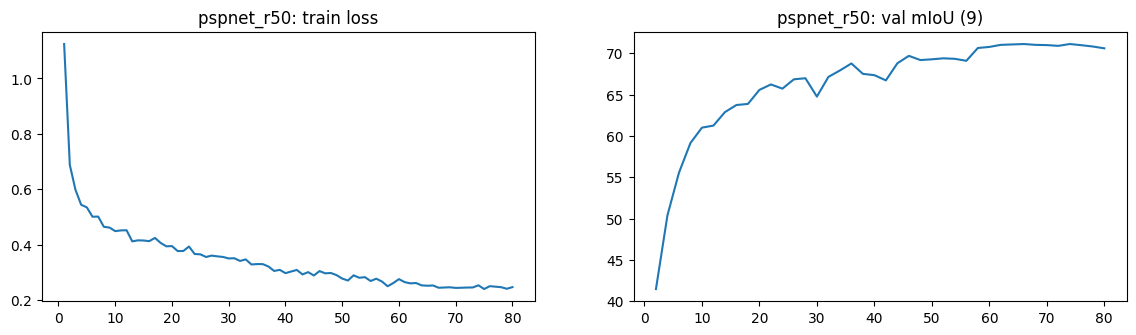

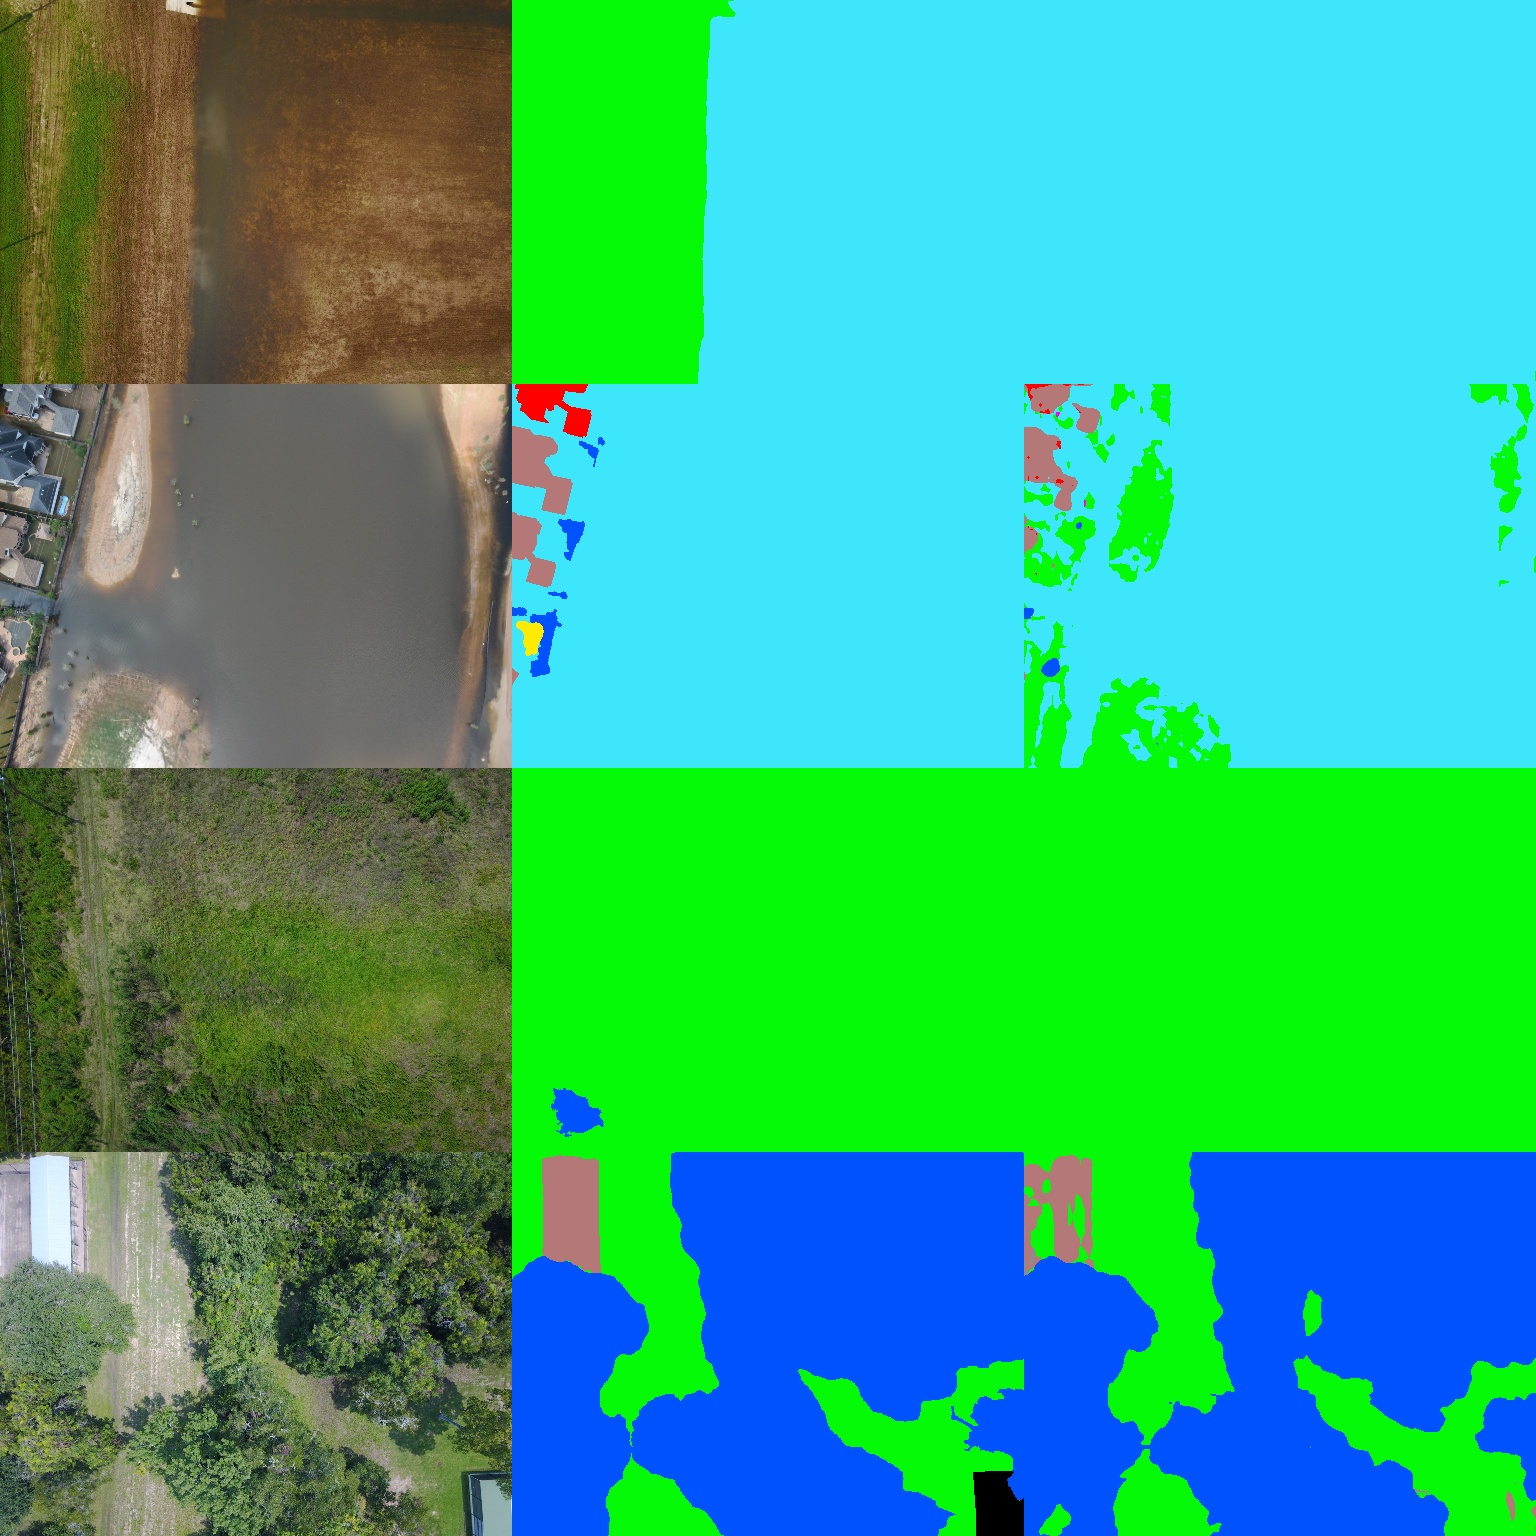


unet_r50_scse_hybrid: test mIoU(9) 75.67  hard-4 67.7  params 33.82M  fps 17.9 (Tesla T4)
   background             42.54
   building-flooded       73.67
   building-non-flooded   80.06
   road-flooded           63.96
   road-non-flooded       83.01
   water                  75.66
   tree                   82.6
   vehicle                65.14
   pool                   68.02
   grass                  88.9


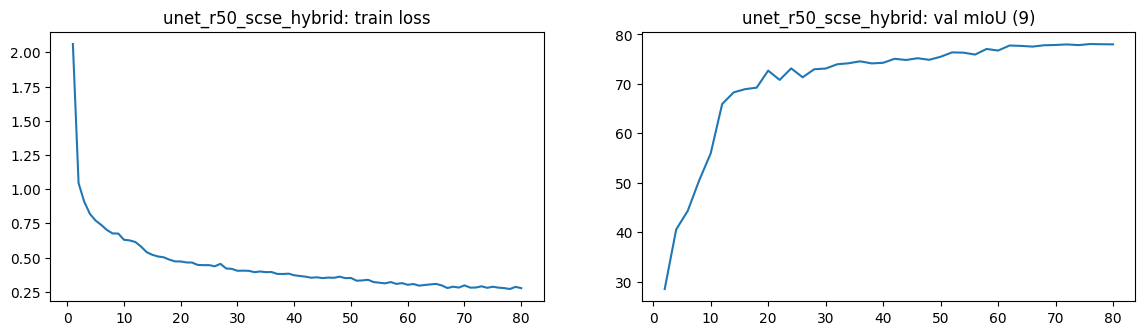

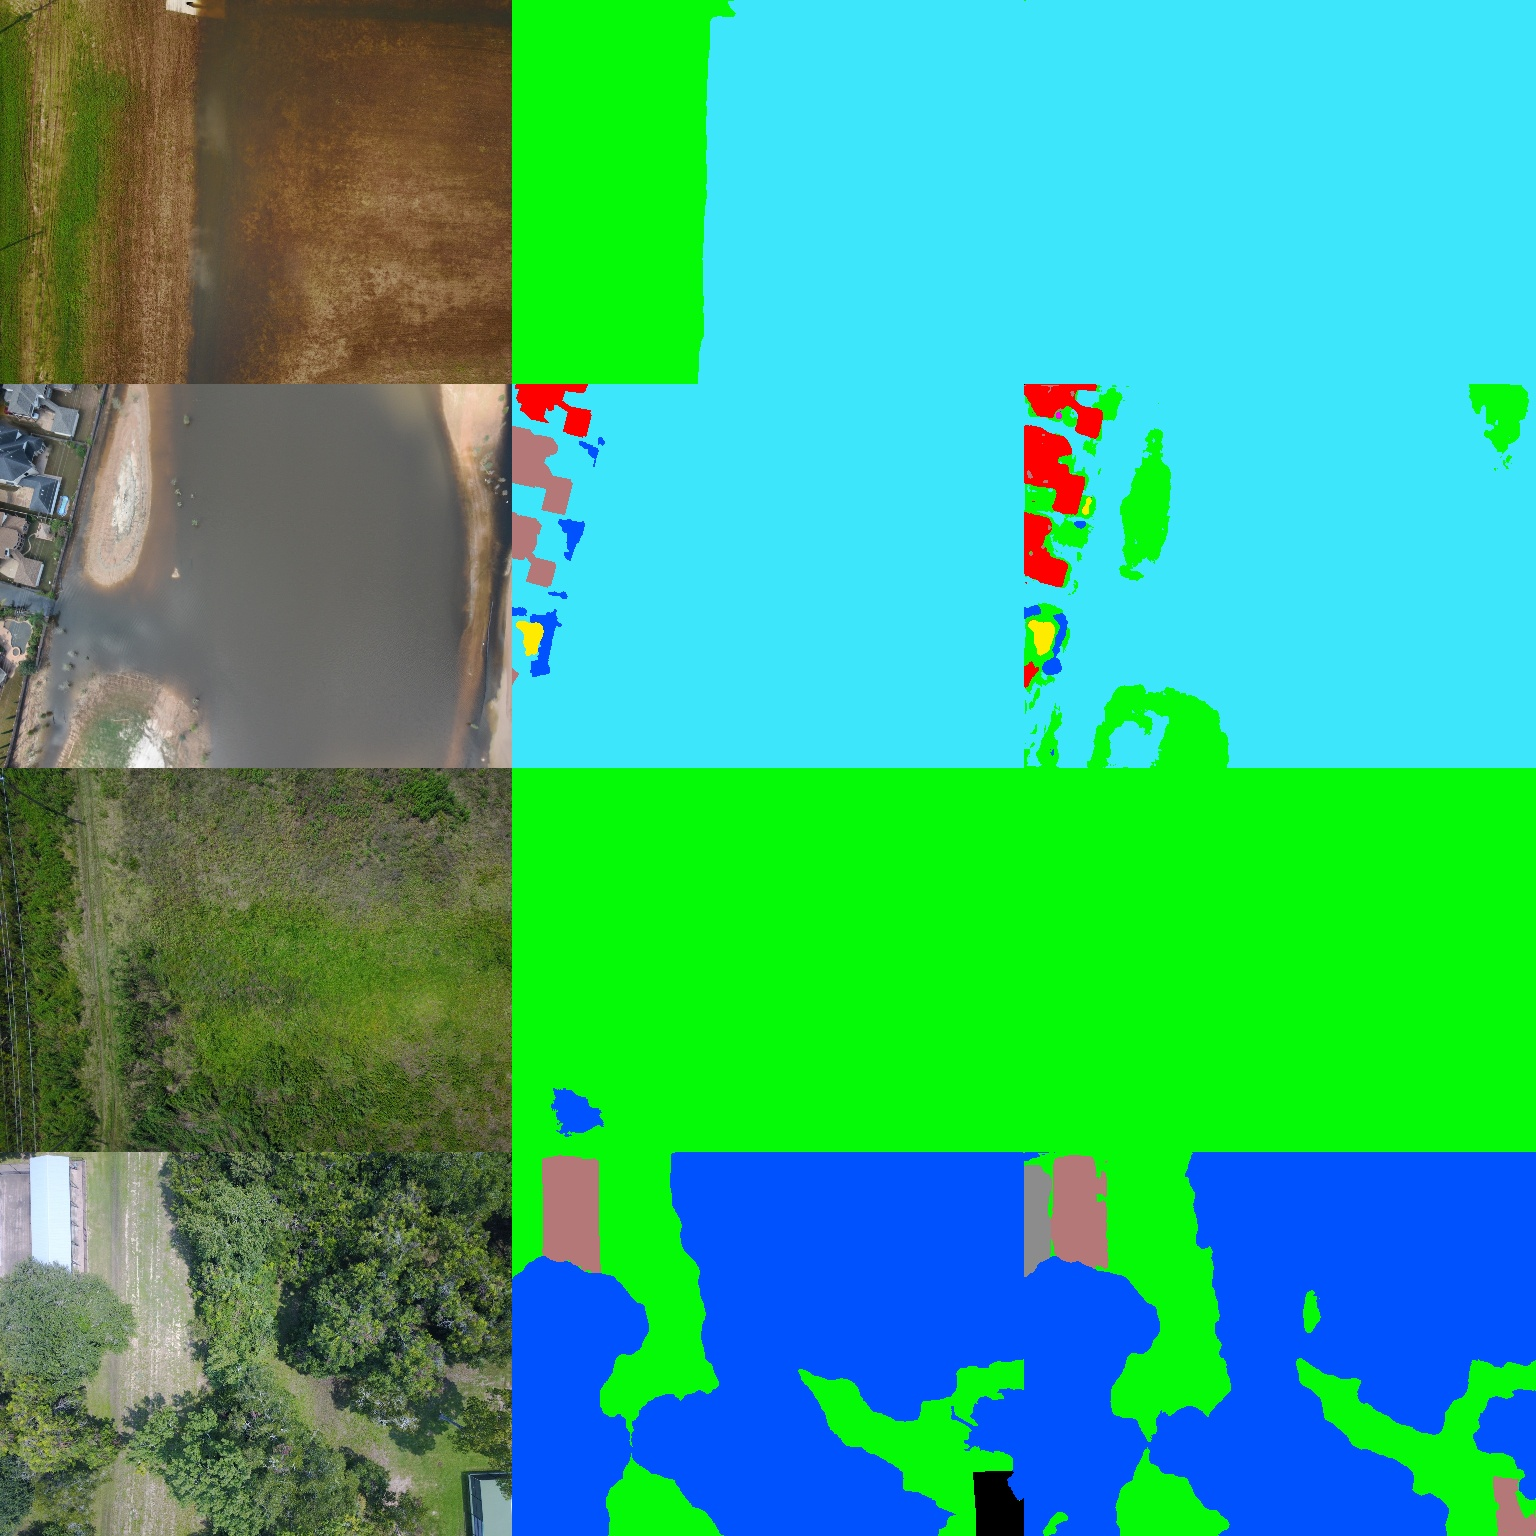

In [18]:
import json, matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display
for RUN in RUNS:
    p = f'{FS}/results/{RUN}.json'
    if not os.path.exists(p):
        print(f'{RUN}: not finished yet'); continue
    r = json.load(open(p))
    print(f"\n{RUN}: test mIoU(9) {r['test']['mIoU9']}  hard-4 {r['hard_class_mIoU']}  "
          f"params {r['params_M']}M  fps {r['fps']} ({r['gpu']})")
    for c, v in r['test']['per_class_IoU'].items():
        print(f'   {c:22s} {v}')
    h = json.load(open(f'{FS}/runs/{RUN}/history.json'))
    ev = [x for x in h if 'val_mIoU9' in x]
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
    ax[0].plot([x['epoch'] + 1 for x in h], [x['loss'] for x in h]); ax[0].set_title(f'{RUN}: train loss')
    ax[1].plot([x['epoch'] + 1 for x in ev], [x['val_mIoU9'] for x in ev]); ax[1].set_title(f'{RUN}: val mIoU (9)')
    plt.show()
    display(IPImage(f'{FS}/runs/{RUN}/test_predictions.jpg', width=1100))  # photo | ground truth | prediction

## 7. Send your results

Downloads 3 small files per model - send all 6 to the person building the table.

In [19]:
from google.colab import files
for RUN in RUNS:
    files.download(f'{FS}/results/{RUN}.json')
    files.download(f'{FS}/runs/{RUN}/history.json')
    files.download(f'{FS}/runs/{RUN}/test_predictions.jpg')
# best.pt (~100 MB each) stays on your Drive - only the winning model's is needed later.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>